# Benchmark: aligned 20-node results


Uses the corrected aligned 20-node benchmark plus its biological-family completion. Historical 20-node records are excluded. Model runs are averaged within each dataset instance for numerical summaries and inference.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
sources = th.load_aligned_sources()
benchmark = sources["benchmark"]
benchmark_biological = sources["benchmark_biological"]
benchmark_data = sources["benchmark_data"]
benchmark_with_biological = sources["benchmark_with_biological"]
benchmark_with_biological = sources["benchmark_with_biological"]
benchmark_with_biological_data = sources["benchmark_with_biological_data"]


## Families and benchmark panels


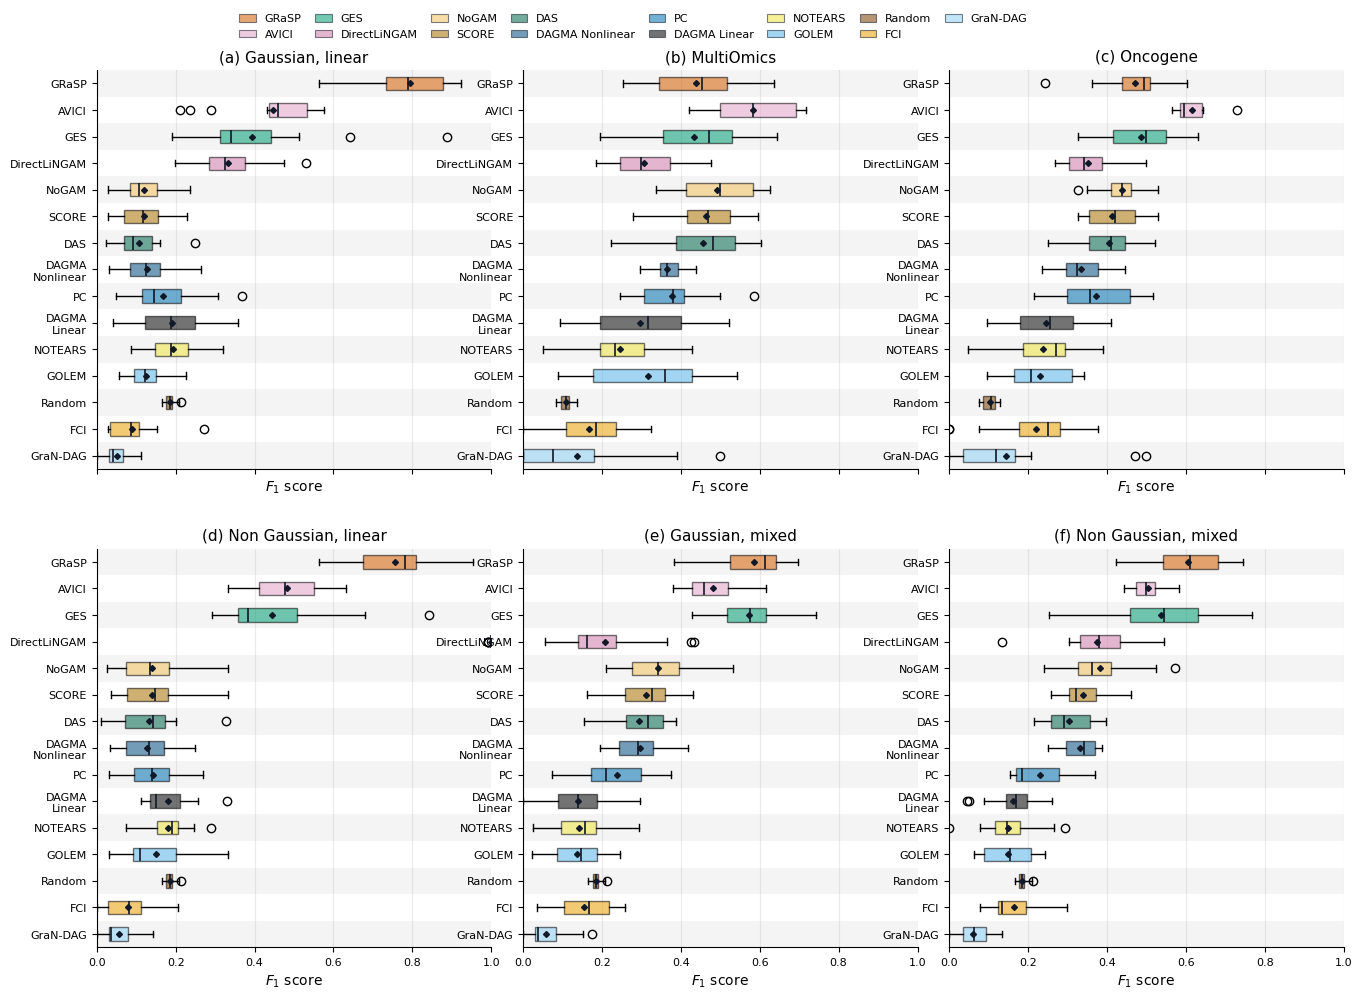

In [2]:
panel_specs = [
    {"title": "Gaussian, linear", "datasets": th.OOD_FAMILIES[0]},
    {"title": "MultiOmics", "datasets": th.TEST_FAMILIES[1]},
    {"title": "Oncogene", "datasets": th.TEST_FAMILIES[2]},
    {"title": "Non Gaussian, linear", "datasets": th.OOD_FAMILIES[2]},
    {"title": "Gaussian, mixed", "datasets": th.OOD_FAMILIES[1]},
    {"title": "Non Gaussian, mixed", "datasets": th.TEST_FAMILIES[0]},
]
order_values = (
    benchmark_with_biological.loc[
        benchmark_with_biological.finished
        & benchmark_with_biological.dataset.isin(th.SIX_FAMILIES)
    ]
    .groupby(["dataset", "dataset_seed", "model"], observed=True)["f1"]
    .mean()
    .groupby(["dataset", "model"], observed=True)
    .mean()
    .groupby("model", observed=True)
    .mean()
    .sort_values(ascending=False)
)
fig, axes, f1_panel = fv.plot_metric_boxplot_grid(
    benchmark_with_biological_data,
    panel_specs,
    metric="f1",
    coverage_policy="all",
    plot_kind="box",
    show_fliers=True,
    whiskers="1.5iqr",
    order_by="manual",
    model_order=order_values.index.tolist(),
    marker_size=4.5,
    capsize=2.5,
    wrap_model_labels=True,
    show_model_bands=True,
    ylim=(0, 1),
    ncols=3,
    sharex=True,
    panel_labels=True,
    xlabel="$F_1$ score",
    legend_ncol=8,
    figsize=(14.5, 10.2),
    font_size=10,
    title_size=11,
)


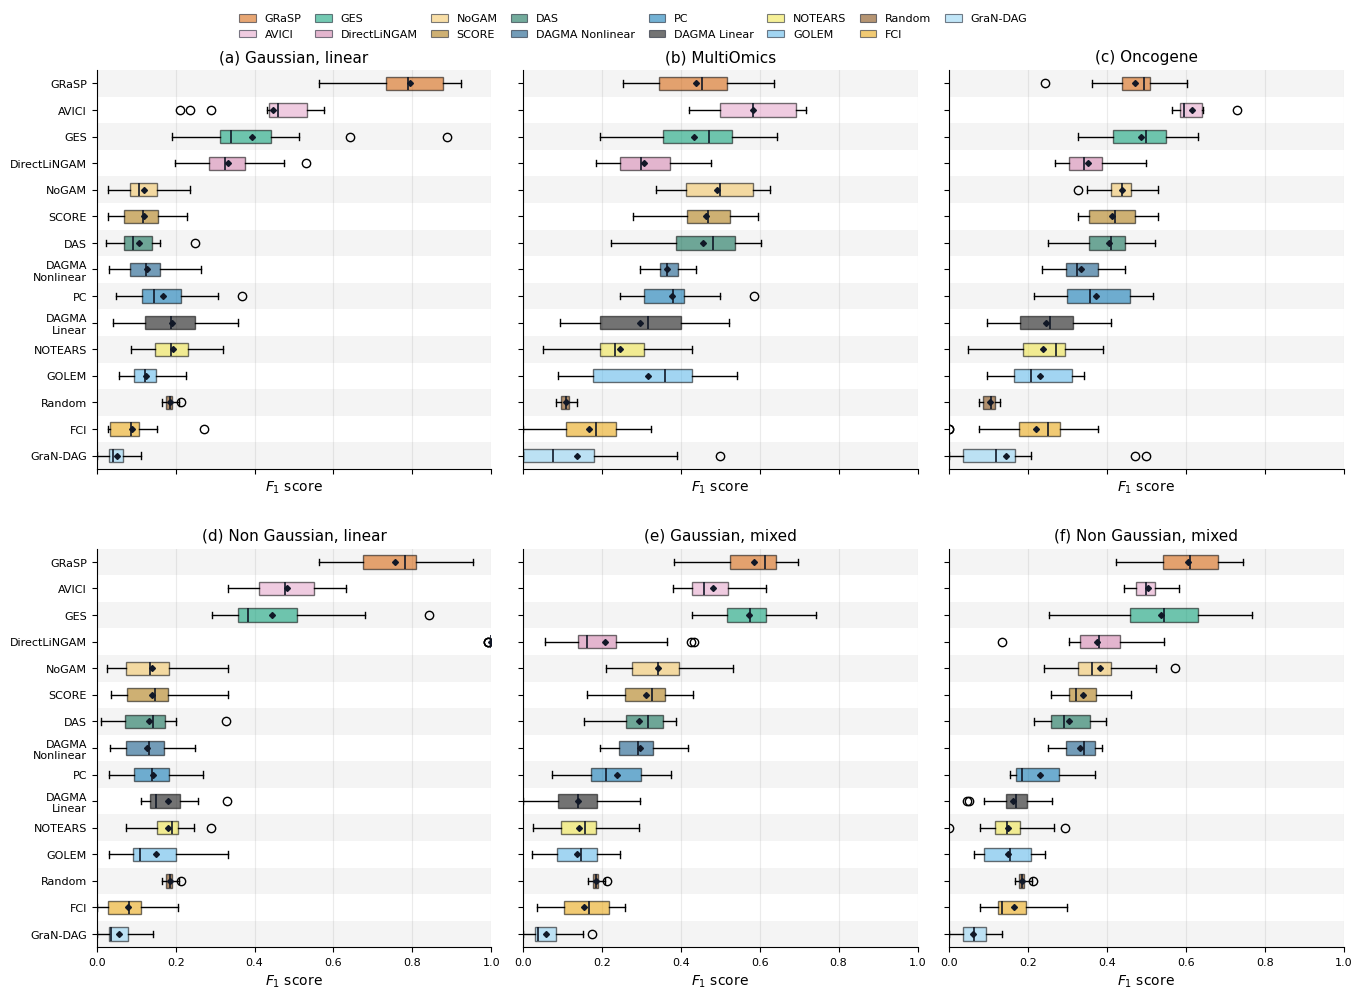

In [3]:
for panel_index, axis in enumerate(axes.ravel()):
    axis.tick_params(axis="y", labelleft=panel_index % 3 == 0)
f1_pdf = th.save_pdf(fig, "F1_six_boxplots_biological.pdf")
display(fig)
plt.close(fig)
paper_panel_specs = [
    {
        "title": "Gaussian, linear",
        "datasets": "20nodes_EB_obsconf0_latconf0_Gaussian_Linear",
    },
    {
        "title": "Gaussian, linear, 6 observed confounders",
        "datasets": "20nodes_EB_obsconf6_latconf0_Gaussian_Linear",
    },
    {
        "title": "Gaussian, linear, 6 latent confounders",
        "datasets": "20nodes_EB_obsconf0_latconf6_Gaussian_Linear",
    },
    {
        "title": "Non Gaussian, linear",
        "datasets": "20nodes_EB_obsconf0_latconf0_NonGaussian_Linear",
    },
    {
        "title": "Gaussian, mixed",
        "datasets": "20nodes_EB_obsconf0_latconf0_Gaussian_Mixed",
    },
    {
        "title": "Non Gaussian, mixed",
        "datasets": "20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed",
    },
]
paper_order = [
    "GRaSP",
    "AVICI",
    "GES",
    "DirectLiNGAM",
    "NoGAM",
    "SCORE",
    "Random",
    "DAGMA_Nonlinear",
    "NOTEARS",
    "DAS",
    "DAGMA_Linear",
    "PC",
    "GOLEM",
    "FCI",
    "GraNDAG",
]


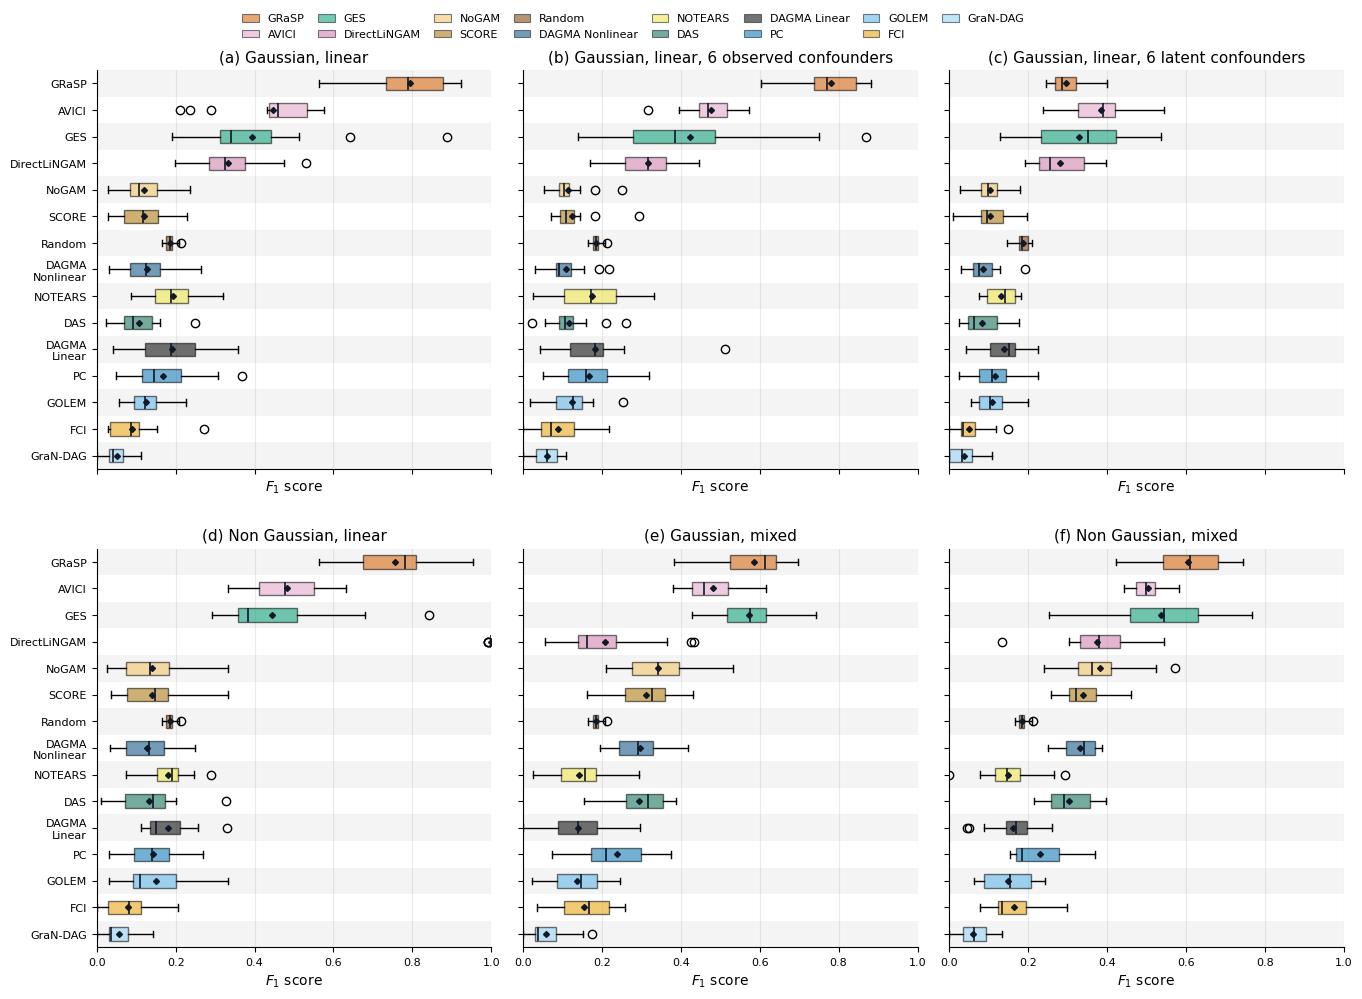

In [4]:
fig_paper_f1, axes_paper_f1, paper_f1_panel = fv.plot_metric_boxplot_grid(
    benchmark_data,
    paper_panel_specs,
    metric="f1",
    coverage_policy="all",
    plot_kind="box",
    show_fliers=True,
    whiskers="1.5iqr",
    order_by="manual",
    model_order=paper_order,
    marker_size=4.5,
    capsize=2.5,
    wrap_model_labels=True,
    show_model_bands=True,
    ylim=(0, 1),
    ncols=3,
    sharex=True,
    panel_labels=True,
    xlabel="$F_1$ score",
    legend_ncol=8,
    figsize=(14.5, 10.2),
    font_size=10,
    title_size=11,
)
for panel_index, axis in enumerate(axes_paper_f1.ravel()):
    axis.tick_params(axis="y", labelleft=panel_index % 3 == 0)
paper_f1_pdf = th.save_pdf(fig_paper_f1, "paper_benchmark_F1_panel.pdf")
display(fig_paper_f1)
plt.close(fig_paper_f1)


## Performance, coverage and paired ranks


In [5]:
benchmark_rank_table = th.benchmark_ranks(benchmark, benchmark_biological)
display(benchmark_rank_table)
benchmark_cells = th.seed_means(benchmark_with_biological, "f1")
benchmark_f1 = (
    benchmark_cells.groupby(["dataset", "model"], observed=True)["f1"]
    .agg(["mean", "std", "size"])
    .reset_index()
)
benchmark_coverage = (
    benchmark_with_biological.groupby(["dataset", "model"], observed=True)
    .agg(planned_fits=("finished", "size"), completed_fits=("finished", "sum"))
    .reset_index()
)
from scipy.stats import friedmanchisquare

friedman_rows = []
for family, group in benchmark_with_biological.groupby("dataset", observed=True):
    eligible = group.groupby("model")["finished"].all()
    cells = benchmark_cells.loc[
        benchmark_cells.dataset.eq(family)
        & benchmark_cells.model.isin(eligible[eligible].index)
    ].pivot(index="dataset_seed", columns="model", values="f1")
    if cells.isna().any().any() or len(cells) != 15:
        raise ValueError(f"Incomplete paired benchmark blocks: {family}")
    result = friedmanchisquare(*(cells[column] for column in cells))
    friedman_rows.append(
        {
            "dataset": family,
            "n_datasets": len(cells),
            "n_models": len(cells.columns),
            "statistic": result.statistic,
            "pvalue": result.pvalue,
        }
    )
benchmark_friedman = pd.DataFrame(friedman_rows)
display(benchmark_friedman)


dataset,Method,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,20nodes_ModMultiOmics_obsconf0_latconf0_Laplace_Mixed,20nodes_ModOncogene_obsconf0_latconf0_Gaussian_Mixed,Median
0,GRaSP,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0
1,AVICI,2.0,3.0,1.0,3.0,2.0,1.0,1.0,2.0,1.0,1.0,1.5
2,GES,2.0,1.0,1.0,3.0,2.0,1.0,1.0,NaN,6.0,2.0,2.0
3,DirectLiNGAM,2.0,9.0,4.0,1.0,4.0,1.0,4.0,3.0,6.0,8.0,4.0
4,SCORE,9.0,4.0,4.0,5.0,4.0,7.0,10.0,4.0,1.0,2.0,4.0
5,DAS,9.0,4.0,4.0,5.0,8.0,7.0,10.0,4.0,1.0,2.0,4.5
6,NoGAM,9.0,4.0,4.0,5.0,4.0,7.0,10.0,11.0,1.0,2.0,4.5
7,PC,5.0,4.0,4.0,5.0,8.0,7.0,5.0,4.0,6.0,2.0,5.0
8,DAGMA Linear,5.0,9.0,10.0,5.0,10.0,5.0,5.0,4.0,6.0,8.0,5.5
9,DAGMA Nonlinear,9.0,4.0,4.0,5.0,4.0,7.0,10.0,11.0,6.0,8.0,6.5


,dataset,n_datasets,n_models,statistic,pvalue
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,15,15,160.333333,6.081550e-27
1,20nodes_EB_obsconf0_latconf0_Gaussian_Mixed,15,15,168.301774,1.508215e-28
2,20nodes_EB_obsconf0_latconf0_HighGaussian_Mixed,15,15,166.407765,3.635978e-28
3,20nodes_EB_obsconf0_latconf0_NonGaussian_Linear,15,15,158.487735,1.428926e-26
4,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,15,15,177.349446,2.231409e-30
5,20nodes_EB_obsconf0_latconf6_Gaussian_Linear,15,15,164.234874,9.968826e-28
6,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,15,15,160.897439,4.683305e-27
7,20nodes_EB_obsconf6_latconf0_Gaussian_Linear,15,14,133.963810,3.390588e-22
8,20nodes_ModMultiOmics_obsconf0_latconf0_Laplac...,15,15,137.504703,2.221489e-22
9,20nodes_ModOncogene_obsconf0_latconf0_Gaussian...,15,15,151.321420,3.910416e-25
